# ПР3: Resnet и классификация Симпсонов

На лекции вы познакомились с историей архитектур нейронных сетей. В этом блокноте мы будем реализовывать одну из самых важных архитектур CNN за последние несколько лет - ResNet.

Для получения дополнительной информации о ResNet вы можете обратиться к [оригинальной статье](https://arxiv.org/pdf/1512.03385.pdf) или прочитать этот [фантастический пост в блоге](https://towardsdatascience.com/understanding-and-visualizing-resnets-442284831be8) на эту тему.

Полученные знания вы сможете сразу применить на практике с реальными данными - построить классификатор персонажей сериала Симпсоны!

# Суть задания


Примерное время выполнения - 12-20 часов (с учётом обучения моделей).

Дедлайн: 31 октября 23:59

## Оценивание

Задания:

Часть работы | Стоимость в баллах
-------------|------------------
Полносвязная сеть | 1 (можно сдать без защиты)
Сверточная сеть | 1 (можно сдать без защиты)
ResNet | 2 (можно сдать без защиты)
Оптимизация | 1
Классификатор Симпсонов с pretrained backbone | 0 + точность
Классификатор, обученный с нуля | 1 + точность
Итого | 10 баллов

Задание сдается в проверяющую систему kaggle. Количество баллов за задание зависит от преодоления порога значения метрики F1 Score, которое выставляется проверяющей системой по закрытой выборке:

Порог | Баллы
-------------|------------------
0.85 | 1
0.89 | 2
0.93 | 3
0.97 | 4

**Модель с точностью ниже порога не оценивается! >:C**

С первого раза набрать оптимальное качество скорее всего не получится. Пробуйте и экспериментируйте. Обратите внимание, что вы можете выполнять **до 2 попыток сдачи на kaggle в день**.

Формула оценивания всей работы:

О = Задание * 0.9 + Тесты на лекцях 4+5+6 * 0.1

### Инструкция перед запуском
1. В Colab выберите **Среда выполнения → Сменить среду выполнения → T4 GPU**.
2. Выполните **Среда выполнения → Выполнить все** (обучение нескольких моделей займёт значительное время).
3. Если скачивание архива Симпсонов не сработает, загрузите `journey-springfield.zip` в `/content/` вручную.
4. Сохраните ноутбук **с результатами выполнения** и выгрузите `simple_cnn_baseline.csv` для Kaggle.
5. **Важно:** код заполнен, но результаты обучения и Kaggle score появятся только после реального запуска. Цель 90% на CIFAR-10 не гарантирована.


# 0: Импорт зависимостей

#### Проверим доступность CUDA

In [7]:
# Блок должен вывести CUDA is available!  Training on GPU ...
#
# Если вывелось что-то другое, необходимо включить GPU:
# Menu > Runtime > Change Runtime Type > Hardware Accelerator > GPU
# Меню > Среда выполнения > Сменить среду выполнения > Аппаратный ускоритель > Графический ускоритель T4

import torch
import numpy as np

train_on_gpu = torch.cuda.is_available()

if not train_on_gpu:
    print('CUDA is not available.  Training on CPU ...')
else:
    print('CUDA is available!  Training on GPU ...')

CUDA is available!  Training on GPU ...


In [8]:
!nvidia-smi

Sat Oct 31 14:47:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

#### Проверим версии Python и библиотек
Посмотрим, какие версии установлены:

In [9]:
!python --version
from importlib.metadata import version
for b in ['torch', 'torchvision', 'tqdm', 'matplotlib', 'seaborn', 'Pillow']:
    print(b + ' version: '+ version(b))

Python 3.13.16
torch version: 2.11.0+cu130
torchvision version: 0.26.0+cu130
tqdm version: 4.67.3
matplotlib version: 3.10.0
seaborn version: 0.13.2
Pillow version: 11.3.0


Сверим с версиями питона и библиотек, на которых работал эталонный ноутбук:

- Python 3.12.12
- torch version: 2.8.0+cu126
- torchvision version: 0.23.0+cu126
- tqdm version: 4.67.1
- matplotlib version: 3.10.0
- seaborn version: 0.13.2
- Pillow version: 11.3.0


 #### Определим константы, которые будем использовать в по ходу ноутбука

In [10]:
# разные режимы датасета
DATA_MODES = ['train', 'val', 'test']

# работаем на видеокарте
from pathlib import Path
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# определим директории с тренировочными и тестовыми файлами
TRAIN_DIR = Path('/content/train') #Path('./data/train/')
TEST_DIR = Path('/content/testset') #Path('./data/testset')

# параметры нормировки изображений по трем каналам перед подачей в модель
# интересно, почему у них именно такие значения?
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]

# все изображения будут масштабированы к размеру 224x224 px
# интересно, почему разрешение именно такое?
RESCALE_SIZE = [224, 224]

In [17]:
import os
import time
import warnings

import numpy as np
from matplotlib import pyplot as plt
from PIL import Image
from sklearn.preprocessing import LabelEncoder

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torch.utils.data import DataLoader, Dataset
try:
    from torchsummary import summary
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchsummary"])
    from torchsummary import summary
from torchvision import datasets
from torchvision.transforms import v2 as T
from tqdm.notebook import tqdm

%matplotlib inline
warnings.filterwarnings(action='ignore', category=DeprecationWarning)

# 1: Реализация ResNet

Внимательному читателю может показаться, что многое из приведённого в этом разделе он уже делал. Однако у повторения работы с MLP и простыми CNN есть важная цель - мы увидим, что на сложных доменах (CIFAR - те же 10 классов, но классы относятся к реальному миру и представлены в виде RGB-изображений) MLP сбоят, а простые свёртки хоть и "легче", но на это ситуацию улучшает не радикально. Зато наглядно видно, как архитектура ResNet даёт качественный скачок, что и делает её актуально даже спустя более чем 10 лет.

### 1.1: Загрузка данных

Напомним, что `torchvision` предоставляет нам прямой доступ к общим наборам данных, что избавляет нас от необходимости самостоятельно загружать данные и писать собственный `DataLoader`. Это очень удобно, когда вы делаете быстрый прототип или проводите исследование. Мы будем использовать классический набор данных CIFAR-10. Запуск этой функции может занять несколько секунд, поскольку ей необходимо загрузить набор данных из интернета.

Многие синтаксисы и концепции загрузки данных, приведенные ниже, надеюсь, вспомнятся из материалов ПР2.5

In [6]:
batch_size = 32
data_root = './data/cifar10'
transform = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Мы установим разделение 80-20 для проверки обучения.
# То есть мы выделим 80 % из 50 тыс. образцов в обучающих данных CIFAR10 в качестве обучающего набора.
# а оставшиеся 20 % - в качестве валидационного набора
train_size = 40_000
val_size = 10_000

dataset = torchvision.datasets.CIFAR10(
    root=data_root,
    train=True,
    download=True,
    transform=transform,
)

assert train_size + val_size <= len(dataset), "Trying to sample too many elements!" \
    "Please lower the train or validation set sizes."
train_set, val_set, _ = torch.utils.data.random_split(
    dataset, [train_size, val_size, len(dataset) - train_size - val_size]
)
classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck',
)

100%|██████████| 170M/170M [08:43<00:00, 326kB/s]


In [7]:
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=2)

Теперь, когда мы загрузили наш набор данных, давайте визуализируем несколько изображений из него!

showing training images


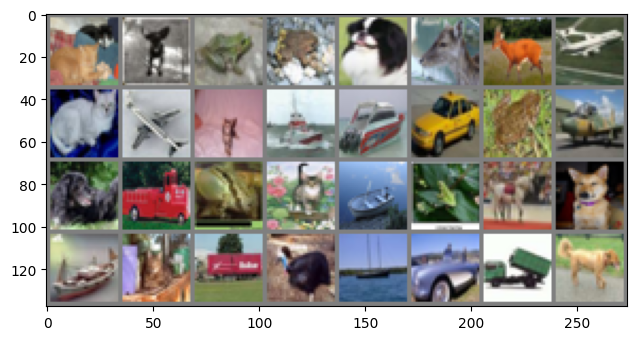


... and their corresponding labels
cat      dog      frog     frog     dog      deer     deer     plane   
cat      plane    cat      ship     ship     car      frog     plane   
dog      truck    frog     cat      ship     frog     horse    dog     
ship     cat      truck    bird     ship     car      truck    dog     


In [8]:
plt.rcParams['figure.figsize'] = [7.5, 7.5]

def show_image(img):
    img = img / 2 + 0.5
    img = img.numpy()
    img = img.transpose([1, 2, 0])
    plt.imshow(img)
    plt.show()

images, labels = next(iter(train_loader))
nrow = 4
print('showing training images')
show_image(torchvision.utils.make_grid(images, nrow=batch_size // nrow))
print('\n... and their corresponding labels')
for idxs in np.array_split(np.arange(batch_size), nrow):
    print(' '.join(f'{classes[labels[j]]:8s}' for j in idxs))

### 1.2: Полносвязная нейронная сеть

Самая базовая структура нейронной сети - это полностью связанная нейронная сеть. Это означает, что каждый нейрон в каждом слое связан с каждым нейроном в предыдущем слое. Это также означает, что каждый пиксель нашего входного изображения связан с каждым нейроном следующего слоя. Напомним, что это всего лишь многослойный перцептрон, с которым мы познакомились в лекции по глубокому обучению.

Сеть MLP/FCNN должна принимать на вход вектор. Однако мы передаем в сеть изображения? Как преобразовать изображение в вектор? Мы можем просто сплющить его! Любое изображение `C x H x W` можно представить в виде вектора значений пикселей размером `C*H*W`, который мы и будем использовать в качестве фактического входа для слоев вашей модели.

Попробуем реализовать этот подход ниже.

In [9]:
class FCNN(nn.Module):
    def __init__(self, layer_dims):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(a, b) for a, b in zip(layer_dims[:-1], layer_dims[1:])])

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        for layer in self.layers[:-1]:
            x = F.relu(layer(x))
        return self.layers[-1](x)


Здесь у вас будет возможность реализовать части циклов обучения и валидации. Если вы столкнетесь с трудностями, обратитесь к циклу обучения из первого домашнего задания — эти циклы обычно достаточно стандартны и имеют много сходств, независимо от используемой модели.

In [10]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

@torch.no_grad()
def compute_accuracy(model, loader):
    model.to(device).eval()
    correct = 0
    for inputs, labels in tqdm(loader, leave=False):
        inputs, labels = inputs.to(device), labels.to(device)
        correct += (model(inputs).argmax(dim=1) == labels).sum().item()
    return correct / len(loader.dataset)

def train(model, train_loader, val_loader, num_epochs, criterion, optimizer, path=None, scheduler=None):
    print('beginning to train model')
    if path:
        os.makedirs(path, exist_ok=True)
    model.to(device)
    history = {'loss': [], 'train_acc': [], 'val_acc': []}
    for epoch in tqdm(range(1, num_epochs + 1)):
        model.train()
        total_loss = 0.0
        start_time = time.perf_counter()
        for inputs, labels in tqdm(train_loader, leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(labels)
        total_loss /= len(train_loader.dataset)
        train_acc = compute_accuracy(model, train_loader)
        val_acc = compute_accuracy(model, val_loader)
        history['loss'].append(total_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        if path:
            torch.save(model.state_dict(), f'{path}/model_ep_{epoch:02d}.pth')
        if scheduler:
            scheduler.step()
        print(f'epoch {epoch:2}', f'loss: {total_loss:.3f}',
              f'time: {time.perf_counter()-start_time:.1f}',
              f'train acc: {train_acc:.4f}', f'val acc: {val_acc:.4f}', sep='\t')
    return history

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


In [11]:
num_epochs = 15
layer_dims = [3072, 100, 10]
fcnn = FCNN(layer_dims)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(fcnn.parameters(), lr=1e-3, momentum=0.9)

In [12]:
train(fcnn, train_loader, val_loader, num_epochs, criterion, optimizer)

beginning to train model


  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

...

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

epoch 15	loss: 1.154	time: 35.9	train acc: 0.6116	val acc: 0.5168


{'loss': [1.8299520777702332,
  1.6171925766944886,
  1.5347478413105011,
  1.4783047092437744,
  1.431772350358963,
  1.3906593094348907,
  1.3567799430847167,
  1.3230361660003662,
  1.2954330289840699,
  1.2679568046569825,
  1.2427251553058625,
  1.2169083254337312,
  1.1956219076633454,
  1.17469255027771,
  1.1537189413547515],
 'train_acc': [0.416225,
  0.45585,
  0.478525,
  0.502075,
  0.517825,
  0.535,
  0.54315,
  0.5595,
  0.569925,
  0.577625,
  0.58465,
  0.597675,
  0.605925,
  0.608625,
  0.611625],
 'val_acc': [0.4196,
  0.4533,
  0.4673,
  0.4848,
  0.5002,
  0.5027,
  0.5039,
  0.5058,
  0.5154,
  0.5119,
  0.5209,
  0.5203,
  0.5191,
  0.5145,
  0.5168]}

В качестве финального наблюдения давайте выведем количество параметров, которые эта сеть обучила.

In [13]:
print(count_parameters(fcnn))

308310


### 1.3: Базовая сверточная нейронная сеть (Convolutional Neural Network)

Вы, вероятно, заметили в приведенном выше примере, что точность на валидации у полносвязной сети была неплохой (определенно выше 10%, которые мы получили бы при случайных угадываниях!), но и не слишком высокой.

С полносвязными нейронными сетями связано две основные проблемы. Первая — это масштабируемость. Поскольку каждый нейрон в каждом слое связан с каждым нейроном в следующем слое, количество весов в каждом слое равно произведению размеров скрытых слоев. Это означает, что для того, чтобы сохранить разумное количество параметров в модели, нам нужно либо ограничить количество слоев, либо уменьшить размер скрытых слоев. Это мешает созданию очень глубоких полносвязных сетей, которые могли бы изучать более сложные зависимости.

Вторая проблема заключается в том, что полносвязные нейронные сети склонны к переобучению, так как они будут изучать разные шаблоны для каждого возможного пикселя во входном изображении — сдвиг объекта на изображении на 1 пиксель может полностью изменить выход сети!

Эти две проблемы привели к созданию сверточных нейронных сетей. Основная идея заключается в том, что вместо соединения всех нейронов друг с другом модель обучает серию _ядер свертки_ (convolutional kernels), которые могут «скользить» по изображению. Эти ядра позволяют применять одни и те же операции к различным частям изображения, что снижает риск переобучения и значительно уменьшает количество необходимых весов. Это может ускорить обучение и позволить создавать более глубокие сети.

Для более подробного объяснения работы сверточных нейронных сетей (CNN) ознакомьтесь с [этой статьей в блоге](https://towardsdatascience.com/a-comprehensive-guide-to-convolutional-neural-networks-the-eli5-way-3bd2b1164a53) и слайдами прошлых лекций

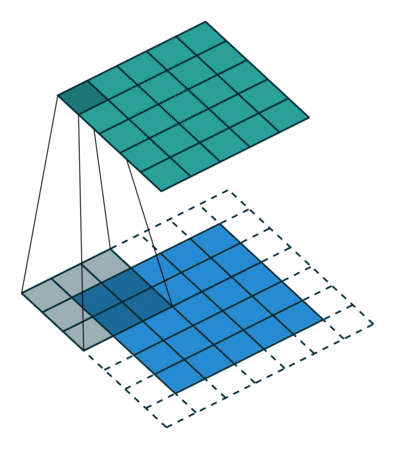

Выше: Пример фильтра (ядра) свертки

Теперь мы реализуем базовую сверточную нейронную сеть. Рекомендуется ознакомиться с документацией PyTorch по [сверточным слоям](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), чтобы узнать больше о том, как следует определять эти слои.

В полносвязной нейронной сети выше нам приходилось выпрямлять каждое изображение (или выпрямлять батч изображений) перед тем, как передать их в линейные слои. Нужно ли нам также выпрямлять изображения перед передачей их в сверточный слой? Подсказка: посмотрите документацию по ссылке выше, чтобы узнать, какой формы тензор ожидает слой `Conv2D` на вход.

In [14]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


In [15]:
num_epochs = 15
cnn = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(cnn.parameters(), lr=1e-3, momentum=0.9)

In [16]:
train(cnn, train_loader, val_loader, num_epochs, criterion, optimizer)

beginning to train model


  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

...

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

epoch 15	loss: 1.029	time: 37.3	train acc: 0.6536	val acc: 0.6104


{'loss': [2.282324971961975,
  1.9642330690383911,
  1.710902330303192,
  1.5631112543106078,
  1.4687064128398895,
  1.3921273312091826,
  1.3308020477294922,
  1.2789157821655273,
  1.232167787694931,
  1.1908472846984863,
  1.149138945579529,
  1.1131758719921112,
  1.0870712110996246,
  1.0549323044300079,
  1.0289309740066528],
 'train_acc': [0.225175,
  0.32785,
  0.41355,
  0.458175,
  0.485675,
  0.52195,
  0.535525,
  0.5541,
  0.57175,
  0.59595,
  0.608325,
  0.626225,
  0.61785,
  0.641425,
  0.653575],
 'val_acc': [0.2287,
  0.3417,
  0.4188,
  0.4572,
  0.4821,
  0.5157,
  0.526,
  0.5411,
  0.5615,
  0.5745,
  0.5828,
  0.5974,
  0.5848,
  0.6012,
  0.6104]}

In [17]:
fcnn_num_params = count_parameters(fcnn)
cnn_num_params = count_parameters(cnn)
print('FCNN Num Params:', fcnn_num_params)
print('CNN Num Params:', cnn_num_params)
print('Ratio:', cnn_num_params/fcnn_num_params)

from torch.utils.flop_counter import FlopCounterMode

# 2. Create dummy input matching your expected input shape
# (Batch size, Channels, Height, Width)
dummy_input = torch.randn(1, 3, 32, 32).to('cuda')

# 3. Calculate FLOPs using the context manager
flop_counter_1 = FlopCounterMode(fcnn)
with flop_counter_1:
    fcnn(dummy_input)

flop_counter_2 = FlopCounterMode(cnn)
with flop_counter_2:
    cnn(dummy_input)

# 4. Display total FLOPs
print(f"Total FLOPs for FCNN: {flop_counter_1.get_total_flops():,}")
print(f"Total FLOPs for CNN: {flop_counter_2.get_total_flops():,}")
print('Ratio:', flop_counter_1.get_total_flops()/flop_counter_2.get_total_flops())

FCNN Num Params: 308310
CNN Num Params: 62006
Ratio: 0.201115760111576
Module             FLOP    % Total
-------------  --------  ---------
FCNN           616.400K    100.00%
 - aten.addmm  616.400K    100.00%
Module                     FLOP    % Total
--------------------  ---------  ---------
CNN                   1303.440K    100.00%
 - aten.convolution   1185.600K     90.96%
 - aten.addmm          117.840K      9.04%
 CNN.conv1             705.600K     54.13%
  - aten.convolution   705.600K     54.13%
 CNN.conv2             480.000K     36.83%
  - aten.convolution   480.000K     36.83%
 CNN.fc1                96.000K      7.37%
  - aten.addmm          96.000K      7.37%
 CNN.fc2                20.160K      1.55%
  - aten.addmm          20.160K      1.55%
 CNN.fc3                 1.680K      0.13%
  - aten.addmm           1.680K      0.13%
Total FLOPs for FCNN: 616,400
Total FLOPs for CNN: 1,303,440
Ratio: 0.4729024734548579


/tmp/ipykernel_2334/862743532.py:14: UserWarning: mods argument is not needed anymore, you can stop passing it
  flop_counter_1 = FlopCounterMode(fcnn)
/tmp/ipykernel_2334/862743532.py:18: UserWarning: mods argument is not needed anymore, you can stop passing it
  flop_counter_2 = FlopCounterMode(cnn)


Мы улучшили точность на валидации, сократив количество параметров на 80%. Отлично!

### 1.4: Использование ResNet для классификации

Сеть, которую мы реализуем здесь, — это остаточная сеть (**ResNet**), вариант сверточной нейронной сети (CNN) и одна из самых важных сетей в современном компьютерной зрении.

Основная идея ResNet заключается в использовании **пропускающих связей** (*skip connection*). В очень глубоких нейронных сетях часто возникает проблема **затухания градиента** (*vanishing gradient problem*), когда обновления во время обратного распространения ошибки умножаются на очень малые числа, из-за чего первые несколько слоев обучаются очень медленно. Пропускающие связи решают эту проблему, позволяя выходам некоторых слоев перескакивать через несколько слоев и добавляться к выходу на более позднем этапе. Это сокращает путь, который должны пройти обновления градиентов, чтобы обновить более ранние слои сети.

Сеть называется остаточной (**residual network**), потому что её **остаточные блоки** (*residual blocks*) вместо обучения функции $f(x)$ обучают **остаток** $f(x) - x$. Входное значение $x$ добавляется обратно с помощью пропуска связи (*skip connection*).

Для получения более подробной информации попробуйте ознакомиться с [оригинальной статьей о ResNet](https://arxiv.org/pdf/1512.03385.pdf) или с [этой отличной статьей в блоге](https://towardsdatascience.com/understanding-and-visualizing-resnets-442284831be8).

Поскольку это достаточно сложная архитектура, мы попросим вас реализовать только один **остаточный блок** (*residual block*) модели ResNet18. Затем мы объединим эти блоки, чтобы построить полную модель ResNet.

In [18]:
class ResNetBlock(nn.Module):

    def __init__(self, in_channels, out_channels, stride=1):
        '''
        Создайте остаточный (residual) блок для архитектуры ResNet18.

        Ожидаемая структура сети:
        - сверточный слой с параметрами:
          - число выходных каналов = out_channels, ядро 3x3, шаг (stride) = stride
        - слой BatchNorm
        - сверточный слой с параметрами:
          - число выходных каналов = out_channels, ядро 3x3, шаг (stride) = 1
        - слой BatchNorm
        - shortcut слой:
          - если шаг (stride) не равен 1 или out_channels не равен in_channels:
            shortcut слой состоит из двух шагов:
            - сверточный слой с параметрами:
              - число входных каналов = in_channels, число выходных каналов = out_channels, ядро 3x3, шаг (stride) = stride
            - слой BatchNorm
          - иначе:
            shortcut слой не выполняет никаких операций (no-op).

        Все сверточные слои должны иметь паддинг 1 и не должны использовать смещение (bias term). Для удобства рассмотрите использование
        предоставленной вспомогательной функции `conv()`.

        При выполнении прямого прохода (forward pass) активация ReLU должна применяться:
        - после первого слоя BatchNorm
        - после добавления второго слоя BatchNorm к shortcut.
        '''
        super().__init__()
        self.conv1 = self.conv(in_channels, out_channels, 3, stride)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = self.conv(out_channels, out_channels, 3, 1)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = (nn.Sequential(self.conv(in_channels, out_channels, 3, stride),
                                       nn.BatchNorm2d(out_channels))
                         if stride != 1 or in_channels != out_channels else nn.Sequential())

    def conv(self, in_channels, out_channels, kernel_size, stride):
        return nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding=1, bias=False)

    def forward(self, x):
        '''
        Выполните прямой проход (forward pass) этого батча данных через остаточный блок.

        x: батч изображений формы (batch_size, num_channels, width, height)
        returns: результат прохождения x через этот блок
        '''
        residual = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + residual)

class ResNet18(nn.Module):
    def __init__(self, num_classes):
        super(ResNet18, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=3,
                               out_channels=64,
                               kernel_size=3,
                               stride=1,
                               padding=1,
                               bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.in_channels = 64
        self.layer1 = self.make_block(out_channels=64, stride=1, rep=2)
        self.layer2 = self.make_block(out_channels=128, stride=2, rep=2)
        self.layer3 = self.make_block(out_channels=256, stride=2, rep=2)
        self.layer4 = self.make_block(out_channels=512, stride=2, rep=2)
        self.linear = nn.Linear(512, num_classes)

    def make_block(self, out_channels, stride, rep):
        layers = []
        for stride in [stride, 1]:
            layers.append(ResNetBlock(self.in_channels, out_channels, stride))
            self.in_channels = out_channels
        return nn.Sequential(*layers)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = F.avg_pool2d(x, 4)
        x = torch.flatten(x, 1)
        x = self.linear(x)
        return x

In [19]:
num_epochs = 15
resnet = ResNet18(num_classes = 10)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(resnet.parameters(), lr=1e-3, momentum=0.9)

Теперь, когда мы определили нашу модель, вы можете использовать функцию из пакета `torchsummary`, чтобы визуализировать, как изображение проходит через сеть и как слои изменяют его форму. Финальный сверточный слой должен выдавать тензор размером `(32, 512, 4, 4)`, который затем усредняется, выпрямляется (flatten) и передается в полносвязный слой, чтобы получить тензор классификационных оценок размером `(32, 10)`. Для оценки предсказаний мы просто берем `argmax` из нашего вывода.


In [20]:
resnet = resnet.to(device)
summary(resnet, input_size = (3, 32, 32), batch_size=32)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [32, 64, 32, 32]           1,728
       BatchNorm2d-2           [32, 64, 32, 32]             128
            Conv2d-3           [32, 64, 32, 32]          36,864
       BatchNorm2d-4           [32, 64, 32, 32]             128
            Conv2d-5           [32, 64, 32, 32]          36,864
       BatchNorm2d-6           [32, 64, 32, 32]             128
       ResNetBlock-7           [32, 64, 32, 32]               0
            Conv2d-8           [32, 64, 32, 32]          36,864
       BatchNorm2d-9           [32, 64, 32, 32]             128
           Conv2d-10           [32, 64, 32, 32]          36,864
      BatchNorm2d-11           [32, 64, 32, 32]             128
      ResNetBlock-12           [32, 64, 32, 32]               0
           Conv2d-13          [32, 128, 16, 16]          73,728
      BatchNorm2d-14          [32, 128,

Эта модель будет обучаться около 20 минут. Убедитесь, что вы подключены к GPU-окружению в Colab или, если у вас есть GPU на компьютере, рассмотрите возможность локального обучения. Обратите внимание, что Colab может прервать соединение с окружением; это не должно стать большой проблемой для этого задания, но убедитесь, что вкладка браузера остается открытой во время обучения моделей.

Реализация преподавателей достигла точности на валидации около 60% после 1 эпохи обучения. Если ваши результаты окажутся значительно хуже, рассмотрите возможность остановки обучения и отладки вашей модели.

In [21]:
train(resnet, train_loader, val_loader, num_epochs, criterion, optimizer, 'checkpoints_resnet')

beginning to train model


  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

...

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

epoch 15	loss: 0.010	time: 72.0	train acc: 0.9990	val acc: 0.8101


{'loss': [1.3615684791088105,
  0.8705447505712509,
  0.6247819772362709,
  0.4347874025762081,
  0.2887353147059679,
  0.18455823739022018,
  0.12919829483553769,
  0.08771605336405337,
  0.05407278375932947,
  0.039694767226511614,
  0.029138055187137798,
  0.025343228634214027,
  0.01861198324074503,
  0.0147674612181494,
  0.009963824278861284],
 'train_acc': [0.614575,
  0.78305,
  0.8492,
  0.907375,
  0.937375,
  0.969,
  0.95675,
  0.971025,
  0.98745,
  0.990925,
  0.995675,
  0.998325,
  0.998125,
  0.995825,
  0.99905],
 'val_acc': [0.5849,
  0.7227,
  0.7501,
  0.7672,
  0.778,
  0.7851,
  0.7597,
  0.7601,
  0.7858,
  0.792,
  0.8015,
  0.8042,
  0.805,
  0.7982,
  0.8101]}

Вот и всё! Просто добавив пропуски связи (*skip connections*), мы значительно улучшили точность классификации по сравнению с обычной CNN!

### 1.5: Оптимизация гиперпараметров и другие трюки

В этом разделе вам предстоит добиться **точности на валидации** не менее **90%** на том же наборе данных CIFAR-10. Ниже мы предоставили код, позволяющий изменить различные параметры модели, процедуру обучения и аугментации данных. Вы можете использовать всё, что угодно, кроме загрузки предварительно обученных моделей. Однако создание собственной архитектуры модели с использованием любых трюков, изученных на занятиях, вполне допустимо.

Вот несколько вещей, которые вы можете попробовать изменить:
- Размер батча  
- Скорость обучения  
- Оптимизатор  
- Количество эпох  
- Преобразования/аугментации изображений  
- Добавление/удаление/модификация сверточных и полносвязных слоев  
- Добавление dropout, batchnorm и т.д.

In [22]:
data_root = './data/cifar10'
train_size = 40_000
val_size = 10_000

## YOUR CODE HERE
## TODO: Измените указанные преобразования и гиперпараметры, если хотите
## Не удаляйте T.Normalize. Если вы хотите изменить нормализацию,
## измените списки mean и std ниже.
batch_size = 128

mean = torch.tensor([0.485, 0.456, 0.406])
std = torch.tensor([0.229, 0.224, 0.225])
transform_train = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomCrop(32, padding=4),
    T.RandomRotation(10),
    T.Normalize(mean, std),
])
## END YOUR CODE

transform_val = T.Compose([
    T.Normalize(mean, std),
])

dataset = datasets.CIFAR10(
    root=data_root,
    train=True,
    download=True,
    transform=T.Compose([
        T.ToImage(),
        T.ToDtype(torch.float32, scale=True),
    ]),
)

assert train_size + val_size <= len(dataset), "Trying to sample too many elements!" \
    "Please lower the train or validation set sizes."
train_split, val_split, _ = torch.utils.data.random_split(
    range(len(dataset)), [train_size, val_size, len(dataset) - train_size - val_size]
)

class CustomTransformDataset(Dataset):
    def __init__(self, dataset, indices, transform):
        self.dataset = dataset
        self.transform = transform
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        x, y = self.dataset[self.indices[idx]]
        return self.transform(x), y

train_set = CustomTransformDataset(dataset, train_split, transform=transform_train)
val_set = CustomTransformDataset(dataset, val_split, transform=transform_val)

train_loader = DataLoader(
    train_set,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)
val_loader = DataLoader(
    val_set,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

Вы можете визуализировать эффекты аугментации данных на обучающем наборе, запустив ячейку ниже:

showing training images


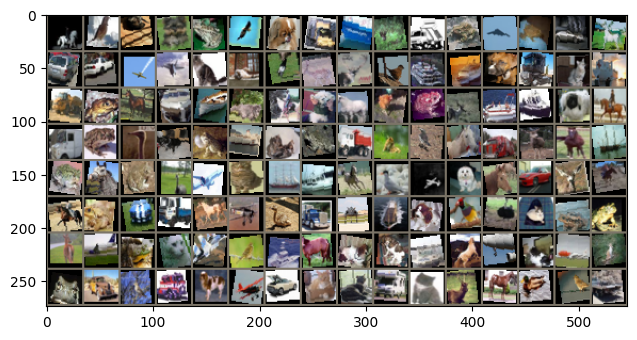


... and their corresponding labels
horse    bird     cat      dog      frog     bird     dog      truck    ship     deer     truck    frog     plane    frog     car      horse   
car      car      plane    plane    cat      cat      bird     deer     deer     bird     ship     ship     dog      truck    cat      ship    
truck    frog     horse    ship     ship     cat      horse    dog      horse    bird     frog     deer     ship     ship     dog      horse   
truck    frog     bird     dog      frog     ship     cat      frog     truck    cat      bird     horse    truck    deer     horse    ship    
frog     horse    frog     bird     plane    cat      ship     ship     horse    bird     plane    dog      horse    car      deer     horse   
horse    frog     car      truck    horse    plane    bird     truck    plane    ship     dog      bird     bird     cat      frog     frog    
deer     plane    frog     cat      plane    bird     ship     horse    dog      cat      ship     h

In [23]:
plt.rcParams['figure.figsize'] = [7.5, 7.5]

def show_image(img):
    img = img * std.reshape(-1, 1, 1) + mean.reshape(-1, 1, 1)
    img = img.numpy()
    img = img.transpose([1, 2, 0])
    plt.imshow(img)
    plt.show()

images, labels = next(iter(train_loader))
nrow = 8
print('showing training images')
show_image(torchvision.utils.make_grid(images, nrow=batch_size // nrow))
print('\n... and their corresponding labels')
classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck',
)
for idxs in np.array_split(np.arange(batch_size), nrow):
    print(' '.join(f'{classes[labels[j]]:8s}' for j in idxs))

In [24]:
# ResNet18 обучается с нуля, без предварительно обученных весов.
final_cnn = ResNet18(num_classes=10).to(device)
print('Trainable parameters:', count_parameters(final_cnn))

Trainable parameters: 12550218


In [25]:
num_epochs = 45
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(final_cnn.parameters(), lr=1e-3, weight_decay=5e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
final_history = train(final_cnn, train_loader, val_loader, num_epochs, criterion,
                      optimizer, 'checkpoints_final_cnn', scheduler)
print('Final validation accuracy:', compute_accuracy(final_cnn, val_loader))
# 90% — целевой порог задания, а не гарантированный результат.


beginning to train model


  0%|          | 0/45 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

...

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

epoch 45	loss: 0.524	time: 96.6	train acc: 0.9942	val acc: 0.9321


  0%|          | 0/79 [00:00<?, ?it/s]

Final validation accuracy: 0.9321


# 2: Классификация Симпсонов

Сегодня вам предстоить помочь телекомпании FOX в обработке их контента. Как вы знаете, сериал "Симпсоны" идет на телеэкранах более 25 лет, и за это время скопилось очень много видеоматериала.

Персонажи менялись вместе с изменяющимися графическими технологиями, и Гомер Симпсон-2018 не очень похож на Гомера Симпсона-1989. В этом задании вам необходимо классифицировать персонажей, проживающих в Спрингфилде. Думаю, нет смысла представлять каждого из них в отдельности.


### 2.1: Загрузка и обработка данных

#### Скачаем изображения по ссылке

In [18]:
!pip -q install gdown torchsummary
!gdown 1q8XYBnKPRT4ubCQss3v3fw6kZaGjmgEf -O /content/journey-springfield.zip


Downloading...
From (original): https://drive.google.com/uc?id=1q8XYBnKPRT4ubCQss3v3fw6kZaGjmgEf
From (redirected): https://drive.google.com/uc?id=1q8XYBnKPRT4ubCQss3v3fw6kZaGjmgEf&confirm=t&uuid=a5ce0137-58ca-4857-9abe-2ee2d6577270
To: /content/journey-springfield.zip
100% 546M/546M [00:08<00:00, 63.5MB/s]


In [19]:
!unzip -q /content/journey-springfield.zip

replace characters_illustration.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


Посмотрите на структуру файлов в папках train и testset.

В train лежат данные, которые мы будем использовать для обучения модели. Изображения персонажей разложены по папкам, которые названы по именам персонажей. Названия папок мы в дальнейшем будет использовать в качестве текстовых меток классов.

В testset находятся изображения, для которых вам надо будет сделать прогноз наиболее вероятного класса.


Для обращения к файлам сформируем списки имен файлов обучающей+валидационнной и тестовой выборок. Это полные имена, включающие путь к файлам.


In [20]:
train_val_files = sorted(list(TRAIN_DIR.rglob('*.jpg')))
test_files = sorted(list(TEST_DIR.rglob('*.jpg')))

In [21]:
train_val_files[:10]

[PosixPath('/content/train/simpsons_dataset/abraham_grampa_simpson/pic_0000.jpg'),
 PosixPath('/content/train/simpsons_dataset/abraham_grampa_simpson/pic_0001.jpg'),
 PosixPath('/content/train/simpsons_dataset/abraham_grampa_simpson/pic_0002.jpg'),
 PosixPath('/content/train/simpsons_dataset/abraham_grampa_simpson/pic_0003.jpg'),
 PosixPath('/content/train/simpsons_dataset/abraham_grampa_simpson/pic_0004.jpg'),
 PosixPath('/content/train/simpsons_dataset/abraham_grampa_simpson/pic_0005.jpg'),
 PosixPath('/content/train/simpsons_dataset/abraham_grampa_simpson/pic_0006.jpg'),
 PosixPath('/content/train/simpsons_dataset/abraham_grampa_simpson/pic_0007.jpg'),
 PosixPath('/content/train/simpsons_dataset/abraham_grampa_simpson/pic_0008.jpg'),
 PosixPath('/content/train/simpsons_dataset/abraham_grampa_simpson/pic_0009.jpg')]

Кодировать имена персонажей в числовые метки класса и обратно будем при помощи `LabelEncoder`.

Для train выборки сформируем список текстовых меток всех изображений - имя родительской директории, которая одновременно является и именем персонажа. Зададим числовые метки классов нашего энкодера при помощи метода `fit`.

Далее будем применять метод `transform` для преобразования текстовых меток в числовые, и метод `inverse_transform` для преобразования числовых меток в текстовые.


In [22]:
label_encoder = LabelEncoder()

train_val_labels = [path.parent.name for path in train_val_files]

label_encoder.fit(train_val_labels)

LabelEncoder()

In [23]:
train_val_labels[:10]

['abraham_grampa_simpson',
 'abraham_grampa_simpson',
 'abraham_grampa_simpson',
 'abraham_grampa_simpson',
 'abraham_grampa_simpson',
 'abraham_grampa_simpson',
 'abraham_grampa_simpson',
 'abraham_grampa_simpson',
 'abraham_grampa_simpson',
 'abraham_grampa_simpson']

Разделим train выборку на обучающую и валидационнную части. Для того, чтобы персонажи были пропорционально представлены в обучающей и валидационнной подвыборках, применим стратификацию по меткам класса.

In [24]:
from sklearn.model_selection import train_test_split

train_files, val_files = train_test_split(train_val_files, test_size=0.25, \
                                          stratify=train_val_labels)

####Создадим Datasets и Dataloaders

Полезная статья, которой мы вдохновились при создании класса `SimpsonsDataset`:
https://jhui.github.io/2018/02/09/PyTorch-Data-loading-preprocess_torchvision/


У нас есть набор файлов-картинок, которые требуется преобразовать в тензоры, и добавить к ним числовые метки классов. Реализуем это с помощью созданного нами класса `SimpsonsDataset`, который из списка файлов создаст необходимый нам Dataset.  

Будем действовать согласно инструкции из документации (https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html#creating-a-custom-dataset-for-your-files):
- наш класс будет наследовать от класса Dataset
- мы переопределим методы `__init__`, `__len__` и `__getitem__`, а также для удобства добавим несколько методов для загрузки и преобразования изображений.

Важно разобраться, что делает метод self.transform_images_to_tensors().

`Compose` объединяет последовательность следующих преобразований:
- `PILToTensor` конвертирует  `PIL Image` в тензор с параметрами в диапазоне $[0, 255]$ (как все пиксели в исходном изображении)
- `ToDtype` преобразует тензор в `FloatTensor` размера ($C \times H \times W$) со значениями пикселей в диапазоне $[0,1]$
- затем `Normalize` производится масштабирование:
$\text{input} = \frac{\text{input} - \text{mean}}{\text{std}} $, <br>      где константы mean и std - средние и дисперсии по каналам в датасете ImageNet
- наконец, `Resize` преобразует картинки к размеру $224 \times 224$ (в описании датасета указано, что картинки разного размера, так как брались напрямую с видео, поэтому следует привести их к одному размеру).

Сейчас аугментация изображений не производится, поэтому для обучающих и валидационных/тестовых изображений производится одинаковая трансформация. В дальнейшем, если вы захотите добавить аугментацию, вы можете сделать это, например, модифицировав метод `transform_images_to_tensors`. Подробнее про доступные трансформации изображений вы можете почитать в документации: https://docs.pytorch.org/vision/main/transforms.html


In [25]:
class SimpsonsDataset(Dataset):
    def __init__(self, files, label_encoder, mode):
        super().__init__()
        # список файлов для загрузки
        self.files = sorted(files)
        # режим работы
        self.mode = mode
        if self.mode not in DATA_MODES:
            print(f"{self.mode} is not correct; correct modes: {DATA_MODES}")
            raise NameError

        self.label_encoder = label_encoder
        self.len_ = len(self.files)

    def __len__(self):
        return self.len_ # сейчас self.__len__() возвращает количество картинок, подаваемых на вход.
        # Если вы решите перевзвесить размеры категорий внутри класса -
        # не забудьте изменить вывод self.__len__()

    def __getitem__(self, index):
        x = self.load_image(self.files[index])
        x = self.transform_images_to_tensors(x)

        if self.mode == 'test':
            return x
        else:
            path = self.files[index]
            y = self.label_encoder.transform([path.parent.name,]).item()
            return x, y

    # принимает путь к файлу изображения и возвращает само изображение
    def load_image(self, file):
        image = Image.open(file)
        image.load()
        return image

    # преобразует изображение в тензор
    def transform_images_to_tensors(self, image):
        if self.mode == 'train':
            transform = T.Compose([
                T.ToImage(),
                T.ToDtype(torch.float32, scale=True),
                T.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
                T.Resize(RESCALE_SIZE),
            ])
        else:
            transform = T.Compose([
                T.ToImage(),
                T.ToDtype(torch.float32, scale=True),
                T.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
                T.Resize(RESCALE_SIZE),
            ])

        return transform(image)


In [26]:
train_dataset = SimpsonsDataset(train_files, label_encoder = label_encoder, mode='train')
val_dataset = SimpsonsDataset(val_files, label_encoder, mode='val')

In [27]:
batch_size = 64

In [28]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
loaders = {'train':train_loader, 'val': val_loader}

#### Посмотрим на изображения персонажей

Напишем функцию для визуализации картинок. Это аналог Imshow, которая будет принимать на вход тензоры

In [29]:
def imshow(inp, title=None, plt_ax=plt, default=False):
    """Imshow для тензоров"""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt_ax.imshow(inp)
    if title is not None:
        plt_ax.set_title(title)
    plt_ax.grid(False)

Проверим, как работает наша функция. Возьмем один батч из лоадера и подадим на вход функции первый тензор из этого батча. Заодно посмотрим, как работает кодировщик меток класса.

Числовая метка класса: 22
Текстовая метка класса: ['marge_simpson']


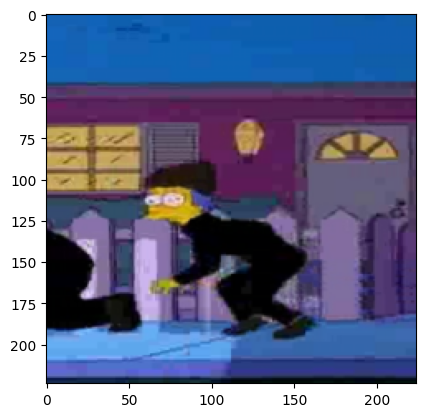

In [30]:
image_tensor, label = next(iter(train_loader))
print(f"Числовая метка класса: {label[0]}")
print(f"Текстовая метка класса: {label_encoder.inverse_transform([label[0],])}")
imshow(image_tensor[0])


Давайте посмотрим на наших героев внутри датасета.

In [31]:
def show_images(n_rows, n_cols, dataset):
  # функция выводит изображения в n_rows рядов и n_cols столбцов
  fig, ax = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 4, n_rows * 4), \
                        sharey=True, sharex=True)

  for fig_x in ax.flatten(): # цикл повторяется (n_rows * n_cols) раз
    random_characters = int(np.random.uniform(0, len(dataset))) # берем случайное число в диапазоне [0; len(dataset))
    im_val, label = dataset[random_characters] # получаем изображение (тензорная форма)
    img_label = " ".join(map(lambda x: x.capitalize(), \
                             label_encoder.inverse_transform([label])[0].split('_')))  # числовую метку класса преобразуем в текстовую и немного отформатируем
    imshow(im_val.data.cpu(), title=img_label, plt_ax=fig_x) # отобразим изображение и метку класса с помощью написанной ранее функции imshow()
    fig_x.set_axis_off()
  return None

**!** Обратите внимание, что возможно, датасет требует дополнительной фильтрации, так как лейблы не всегда точно соответствуют картинкам. Очистка датасета - это один из способов повысить качество модели. Этим можно будет заняться при выполнении задания.

Запустим написанную функцию.

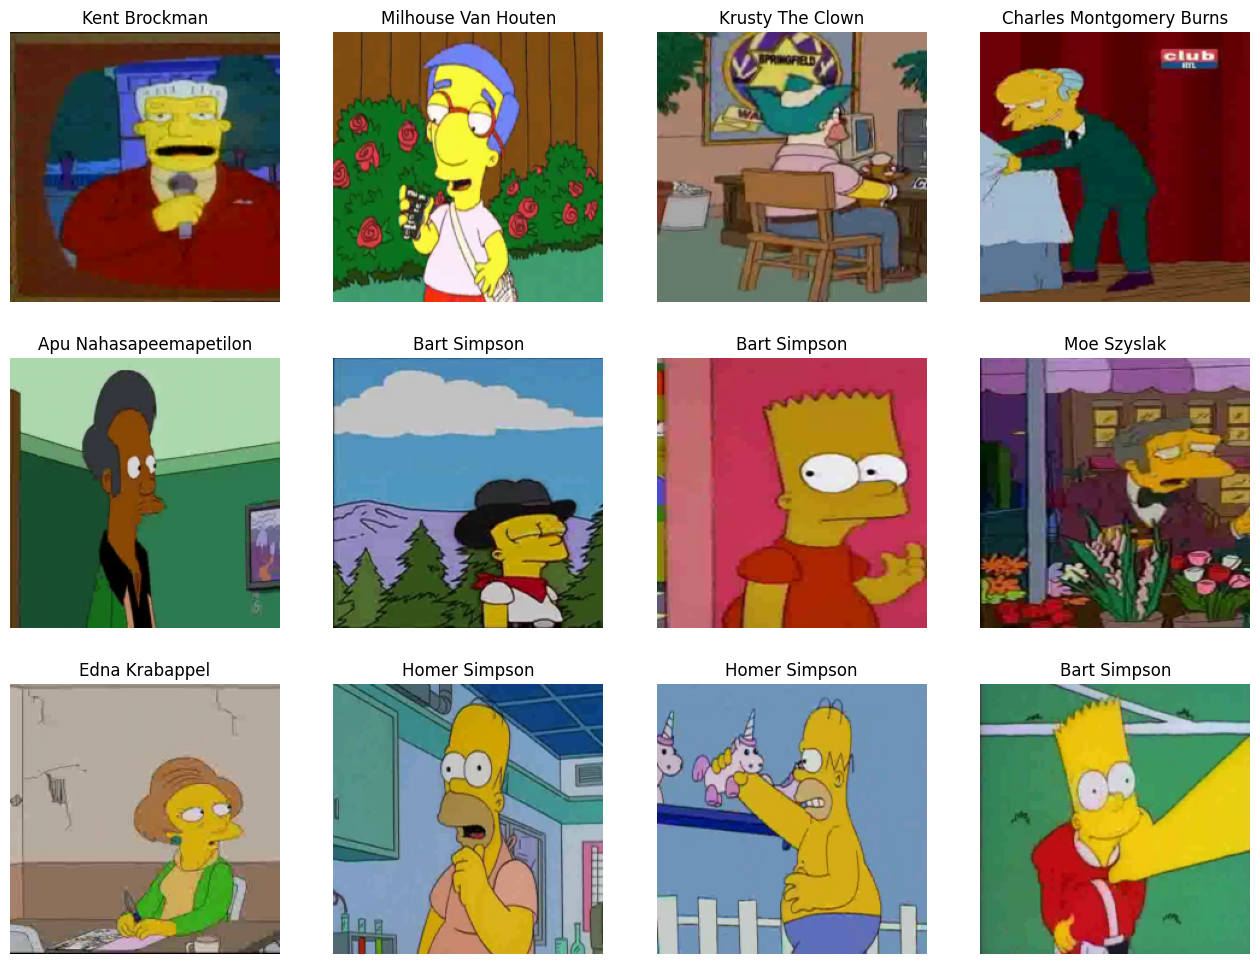

In [32]:
show_images(n_rows = 3, n_cols = 4, dataset = train_dataset)

## 2.2 Построение нейросети

Запустить данную сеть будет вашим первым заданием в этой части, чтобы было проще участвовать в соревновании.

Данная архитектура будет очень простой и нужна для того, чтобы установить базовое понимание и получить простенький сабмит на Kaggle.

#### Модель

In [33]:
class SimpleCnn(nn.Module):
    """
    Очень простая сверточная нейронная сеть для классификации изображений.

    Эта сеть состоит из пяти сверточных слоев, каждый из которых
    включает в себя операцию свертки, функцию активации ReLU и операцию
    пулинга (max-pooling). На выходе используется полносвязный слой
    для классификации на заданное количество классов.

    Параметры:
    ----------
    n_classes : int
        Количество классов для классификации.

    Примечание:
    ----------
    Входные изображения должны иметь размерность (3, H, W), где
    3 - слои rgb для цветной картинки, а H и W - высота и ширина изображения,
    соответственно. Размер выходного тензора будет равен (n_classes).

    Методы:
    -------
    forward(x):
        Пропускает входные данные через сеть и возвращает логиты для
        каждого класса.
    """
    def __init__(self, n_classes):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv4 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv5 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=96, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.out = nn.Linear(96 * 5 * 5, n_classes)


    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)

        x = x.view(x.size(0), -1)
        logits = self.out(x)
        return logits

*Описание слоев*:

1. размерность входа: $3\times 224 \times 224$
2. размерность после 1-го слоя (Conv2d + ReLU + MaxPool2d):  $8 \times 111 \times 111$
3. после 2-го слоя: $16 \times 54 \times 54$
4. после 3-го слоя: $32 \times 26 \times 26$
5. после 4-го слоя: $64 \times 12 \times 12$
6. после 5-го слоя: $96 \times 5 \times 5$
7. после полносвязного слоя (выход модели): количество классов

In [34]:
model_simple_cnn = SimpleCnn(n_classes=len(np.unique(train_val_labels)))
model_simple_cnn.to(DEVICE)
summary(model_simple_cnn, (3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [-1, 8, 222, 222]             224
              ReLU-2          [-1, 8, 222, 222]               0
         MaxPool2d-3          [-1, 8, 111, 111]               0
            Conv2d-4         [-1, 16, 109, 109]           1,168
              ReLU-5         [-1, 16, 109, 109]               0
         MaxPool2d-6           [-1, 16, 54, 54]               0
            Conv2d-7           [-1, 32, 52, 52]           4,640
              ReLU-8           [-1, 32, 52, 52]               0
         MaxPool2d-9           [-1, 32, 26, 26]               0
           Conv2d-10           [-1, 64, 24, 24]          18,496
             ReLU-11           [-1, 64, 24, 24]               0
        MaxPool2d-12           [-1, 64, 12, 12]               0
           Conv2d-13           [-1, 96, 10, 10]          55,392
             ReLU-14           [-1, 96,

## 2.3 Функции для работы с моделью

#### Напишите функции для работы с моделью

Обратите внимание, что метрика, которую необходимо оптимизировать в конкурсе -- `f1-score`.

Ниже приводится код для вычисления целевой метрики.

In [35]:
from sklearn.metrics import f1_score
# пример расчета: f1 = f1_score(actual_labels, y_predicted, average='micro')

В этом задании может быть полезным сделать, чтобы функция валидации и, возможно, функция обучения на одной эпохе возвращали векторы/тензоры:
- предсказанного наиболее вероятного класса
- и фактических меток класса для каждого объекта.

Сама метрика f1, при этом, будет вычисляться не внутри функции, а вне ее, сопоставляя прогнозные и фактические значения, полученные из вывода функции.

Это поможет проанализировать, при предсказании каких классов модель ошибается чаще. Также такой подход может использоваться для обнаружения изображений, которые модель классифицирует неверно.

Напишите функции:
- для обучения модели на одной эпохе
- для валидации модели на одной эпохе
- для реализации полного цикла обучения

In [36]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, y_true, y_pred = 0., [], []
    for x, y in tqdm(loader, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(y)
        y_true.extend(y.cpu().tolist())
        y_pred.extend(logits.argmax(1).detach().cpu().tolist())
    return running_loss / len(loader.dataset), f1_score(y_true, y_pred, average='micro')


In [37]:
@torch.no_grad()
def validate_one_epoch(model, loader, criterion):
    model.eval()
    running_loss, y_true, y_pred = 0., [], []
    for x, y in tqdm(loader, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        running_loss += criterion(logits, y).item() * len(y)
        y_true.extend(y.cpu().tolist())
        y_pred.extend(logits.argmax(1).cpu().tolist())
    return running_loss / len(loader.dataset), f1_score(y_true, y_pred, average='micro')


In [38]:
def fit_simpsons(model, loaders, criterion, optimizer, epochs=12, scheduler=None):
    history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}
    best_f1 = -1
    for epoch in range(1, epochs + 1):
        train_loss, train_f1 = train_one_epoch(model, loaders['train'], criterion, optimizer)
        val_loss, val_f1 = validate_one_epoch(model, loaders['val'], criterion)
        for key, value in zip(history, [train_loss, val_loss, train_f1, val_f1]):
            history[key].append(value)
        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), 'best_simpsons_model.pth')
        if scheduler is not None:
            scheduler.step()
        print(f'Epoch {epoch}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | train F1 {train_f1:.4f} | val F1 {val_f1:.4f}')
    model.load_state_dict(torch.load('best_simpsons_model.pth', map_location=DEVICE, weights_only=True))
    print(f'Best validation micro-F1: {best_f1:.4f}')
    return history


## 2.4 Применение модели к данным

#### Применение модели к данным

In [39]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_simple_cnn.parameters(), lr = 1e-3)

Запустите обучение сети

In [40]:
simpsons_history = fit_simpsons(model_simple_cnn, loaders, criterion, optimizer, epochs=12)

  0%|          | 0/246 [00:00<?, ?it/s]

  0%|          | 0/82 [00:00<?, ?it/s]

Epoch 1/12 | train loss 2.6128 | val loss 2.0147 | train F1 0.2780 | val F1 0.4524


  0%|          | 0/246 [00:00<?, ?it/s]

  0%|          | 0/82 [00:00<?, ?it/s]

...

  0%|          | 0/82 [00:00<?, ?it/s]

Epoch 11/12 | train loss 0.1220 | val loss 1.2370 | train F1 0.9615 | val F1 0.8000


  0%|          | 0/246 [00:00<?, ?it/s]

  0%|          | 0/82 [00:00<?, ?it/s]

Epoch 12/12 | train loss 0.0982 | val loss 1.3631 | train F1 0.9680 | val F1 0.8002
Best validation micro-F1: 0.8013


Постройте график динамики метрик модели по ходу обучения

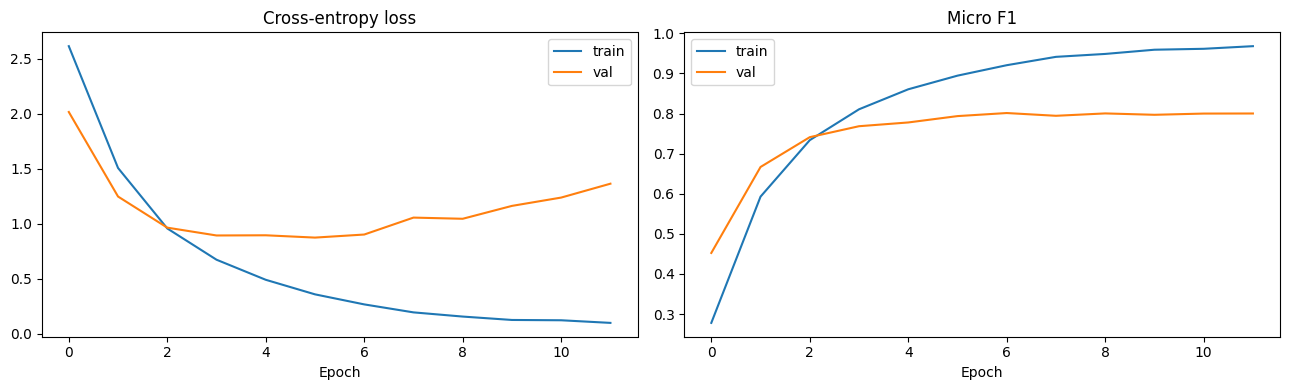

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(simpsons_history['train_loss'], label='train')
axes[0].plot(simpsons_history['val_loss'], label='val')
axes[0].set_title('Cross-entropy loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(simpsons_history['train_f1'], label='train')
axes[1].plot(simpsons_history['val_f1'], label='val')
axes[1].set_title('Micro F1'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout(); plt.show()

### Ну и что теперь со всем этим делать?

![alt text](https://www.indiewire.com/wp-content/uploads/2014/08/the-simpsons.jpg)

Сделаем классную визуализацию,  чтобы посмотреть насколько сеть уверена в своих ответах.

In [42]:
import matplotlib.patches as patches
from matplotlib.font_manager import FontProperties

@torch.no_grad()
def show_images2(n_rows, n_cols, dataset, model):
  # функция выводит изображения в n_rows рядов и n_cols столбцов
  fig, axs = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 4, n_rows * 4), \
                        sharey=True, sharex=True)

  for fig_x in axs.flatten(): # цикл повторяется (n_rows * n_cols) раз
    random_characters = int(np.random.uniform(0, len(dataset))) # берем случайное число в диапазоне [0; len(dataset))
    im_val, label = dataset[random_characters] # выводим изображение (тензорная форма)
    img_label = " ".join(map(lambda x: x.capitalize(), \
                             label_encoder.inverse_transform([label])[0].split('_')))  # числовую метку класса преобразуем в текстовую и немного отформатируем
    imshow(im_val.data.cpu(), title=img_label, plt_ax=fig_x) # отобразим изображение и метку класса с помощью написанной ранее функции imshow()

    # ниже представлен код для добавления на изображение подписи с вероятностью класса
    actual_text = "Actual : {}".format(img_label)


    font0 = FontProperties()
    font = font0.copy()

    # наша модель возвращает логиты, поэтому для получения вероятностей классов не забываем применить softmax:
    prob_pred = nn.functional.softmax(model(im_val.unsqueeze(0).to(DEVICE)), dim = -1).cpu().numpy()

    predicted_proba = np.max(prob_pred)*100 # берем максимальную вероятность класса
    y_pred = np.argmax(prob_pred) # берем числовую метку класса, для которого вероятность максимальна

    predicted_label = " ".join(map(lambda x: x.capitalize(), \
                             label_encoder.inverse_transform([y_pred])[0].split('_')))
    predicted_text = "{}:\n {:.1f}%".format(predicted_label, predicted_proba)

    fig_x.add_patch(patches.Rectangle((0, 190), 7*len(predicted_label), 25,color='white'))
    fig_x.text(2, 195, predicted_text , horizontalalignment='left', fontproperties=font,
                    verticalalignment='top',fontsize=8, color='black',fontweight='bold')
    fig_x.set_axis_off()

  return None

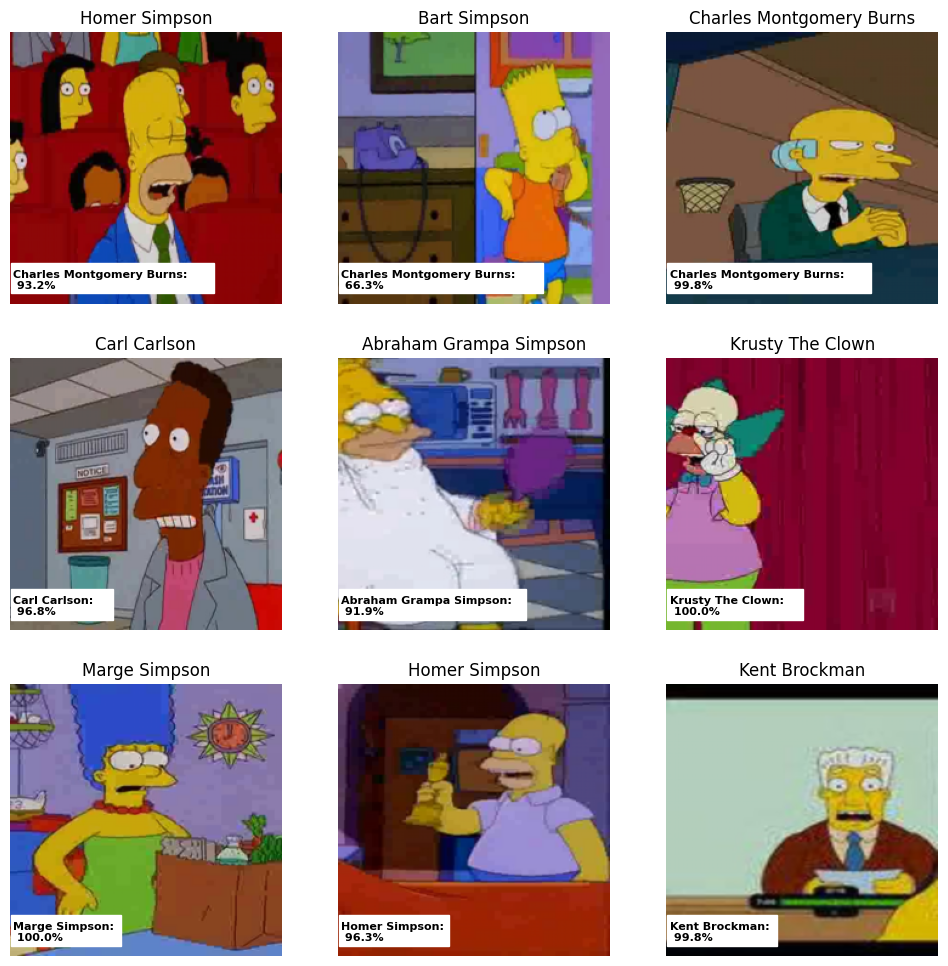

In [43]:
show_images2(n_rows = 3, n_cols = 3, dataset = val_dataset, model = model_simple_cnn)

## 2.5 Submit на Kaggle

![alt text](https://i.redd.it/nuaphfioz0211.jpg)

Создадим loader для тестовых данных

In [44]:
test_dataset = SimpsonsDataset(test_files, label_encoder = label_encoder, mode="test")
test_loader = DataLoader(test_dataset, shuffle=False, batch_size=64)

Воспользуемся функцией predict, которая возвращает предсказанные числовые метки для всех объектов в лоадере.

In [45]:
def predict(model, loader):
    model.eval()
    all_predictions = torch.tensor([]).to(DEVICE).int()
    print("Test mode...")

    for inputs in tqdm(loader):
        inputs = inputs.to(DEVICE)

        with torch.no_grad():
            outputs = model(inputs)
            predictions = outputs.argmax(-1).int()
            all_predictions = torch.cat((all_predictions, predictions), 0)

    return all_predictions.cpu()

Получем предсказание меток классов для тестовых данных:

In [46]:
predicted_numeric_labels = predict(model_simple_cnn, test_loader)

Test mode...


  0%|          | 0/16 [00:00<?, ?it/s]

и преобразуем их в текстовые метки:

In [47]:
predicted_text_labels = label_encoder.inverse_transform(predicted_numeric_labels)

Загрузим пример файла для загрузки на Kaggle (проверьте путь, по которому у вас лежит файл sample_submission.csv и при необходимости скорректируйте путь в коде ниже):

In [48]:
import pandas as pd
sample_submission = pd.read_csv("/content/sample_submission.csv")
sample_submission.head(10)

,Id,Expected
0,img0.jpg,bart_simpson
1,img1.jpg,bart_simpson
2,img2.jpg,bart_simpson
3,img3.jpg,bart_simpson
4,img4.jpg,bart_simpson
5,img5.jpg,bart_simpson
6,img6.jpg,bart_simpson
7,img7.jpg,bart_simpson
8,img8.jpg,bart_simpson
9,img9.jpg,bart_simpson


In [49]:
my_submission = pd.DataFrame({'Id': [path.name for path in test_files], 'Expected': predicted_text_labels})
my_submission.head(10)

,Id,Expected
0,img0.jpg,nelson_muntz
1,img1.jpg,bart_simpson
2,img10.jpg,ned_flanders
3,img100.jpg,chief_wiggum
4,img101.jpg,apu_nahasapeemapetilon
5,img102.jpg,kent_brockman
6,img103.jpg,edna_krabappel
7,img104.jpg,chief_wiggum
8,img105.jpg,lisa_simpson
9,img106.jpg,kent_brockman


In [50]:
# Проверяем формат и порядок колонок перед отправкой в Kaggle.
assert len(my_submission) == len(test_files)
assert not my_submission.isna().any().any()
assert my_submission['Id'].is_unique
print('Submission ready:', my_submission.shape)
display(my_submission.head())

Submission ready: (991, 2)


,Id,Expected
0,img0.jpg,nelson_muntz
1,img1.jpg,bart_simpson
2,img10.jpg,ned_flanders
3,img100.jpg,chief_wiggum
4,img101.jpg,apu_nahasapeemapetilon


In [51]:
my_submission.to_csv('simple_cnn_baseline.csv', index=False)

## 2.6 Приключение?

А теперь самое интересное, мы сделали простенькую сверточную сеть и смогли отправить сабмит, но получившийся score нас явно не устраивает. Надо с этим что-то сделать.

Вам предлагается творческая и исследовательская свобода в том, как вы будете улучшать score модели. Вот некоторые направления, которые вы, возможно, захотите попробовать:
1. Работа с датасетом:
* Попробуйте увеличить разнообразие обучающей выборки при помощи аугментации ([ссылка 1](https://habr.com/ru/companies/smartengines/articles/264677/), [ссылка 2](https://www.geeksforgeeks.org/python-data-augmentation/));
* Используя результаты функции eval_one_epoch, вы можете посмотреть, как метрика f1-score внутри класса связана с размером самого класса в обучающей выборке. Скорее всего, вы заметите прямую зависимость. Решением может быть увеличение размеров слабо представленных классов. Сделать это можно, вручную добавив этот функционал в SimpsonsDataset или воспользовавшись инструментом WeightedRandomSampler.

* Также вы можете изучить, какие изображения модель классифицирует неверно. Можно просто посмотреть неверно классифицированные изображения в валидационном датасете. Можно попробовать более фундаментальный подход - создать dataloader из всех изображений обучающей и валидационной выборки в SimpsonsDataset c режимом 'val', прогнать данные через обученную модель simple_cnn. Более того, можно обучить несколько моделей с разной архитектурой, и прогнать объединенный датасет через все эти модели - и выделить те изображения, в классификации которых ошиблись несколько моделей.

* Это поможет понять, как качество и чистота исходных данных влияет на результаты обучения модели. Если вы обнаружите ошибки в simpsons_dataset и решите их исправить или удалить некоторые изображения из обучающей выборки - сделайте это в ноутбуке, чтобы при проверке можно было повторить результаты работы вашего кода.  

2. Работа с архитектурой сети:
* учим дольше и изменяем (подбираем) гиперпараметры: learning rate, batch size, нормализация картинки и вот это всё;
* Используем силу transfer learning;
* Добавление/удаление свёрточных и полносвязных слоёв;
* А еще есть же пулинги и батч-норм!

3. Улучшение оптимизации:
* ну разве Адам наше все? [adamW](https://www.fast.ai/2018/07/02/adam-weight-decay/) для практика, [статейка для любителей](https://openreview.net/pdf?id=ryQu7f-RZ) (очень хороший анализ), [наши ](https://github.com/MichaelKonobeev/adashift/) эксперименты для заинтересованных.

4. Наконец, возможно, стоит подумать об ансамблях

## Формат сдачи
Сдача результатов модели происходит в [конкурсе от Deep Learning School на платформе kaggle.com](https://www.kaggle.com/competitions/simpsons4/data).

Для выполнения задания необходимо выполнить следующие шаги.
 * Зарегистрироваться на платформе kaggle.com. Процесс выставления оценок будет проходить при подведении итогового рейтинга. Пожалуйста, укажите во вкладке Team -> Team name свои имя и фамилию в формате Имя_Фамилия. Например, "Иван_Петров" или "Ivan_Petrov". И обязательно напишите этот имя в текстовое поле, когда будете прикреплять сдавать задание в SmartLMS!
 * Решить конкурс, получить файл с ответами в формате .csv и сдать его в конкурс. С первого раза набрать оптимальное качество скорее всего не получится. Пробуйте и экспериментируйте. Обратите внимание, что вы можете выполнять до 2 попыток сдачи на kaggle в день.
 * После окончания соревнования отправить в итоговый ноутбук с решением (в следующей вкладке). Получение вашего итогового Score должно быть воспроизводимо.

Рекомендуем планировать своё время так, чтобы перед дедлайном осталось хотя бы 2 дня на оформление конечного ноутбука с решением, чтобы он был чистым и понятным. Просим подробно писать, что вы делаете и зачем вы это делаете. Сам ноутбук не оценивается, но мы можем проверить ноутбук, например, на предмет списывания. Пожалуйста, выполняйте задание честно.

Также Для сдачи задания необходимо прикрепить в задание в SmartLMS ссылку на репозиторий в git.miem.hse.ru, содержащий ноутбук с сохранёнными результатами выполнения ячеек. Также необходимо прикрепить скриншот с платформы Kaggle, на котором будет видно имя профиля и F1-score вашей модели

Для получения полного балла необходимо очно защитить работу

Форма для сдачи результатов позже появится в SmartLMS.

Штрафные коэффициенты оценивания при просрочке:

-|-
----|---
От 12 часов до 7 дней после дедлайна | 0.8
От 7 до 14 дней | 0.6
От 14 дней до конца модуля | 0.4